## Profiles with symbolic Python

In [1]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [12]:
from sympy import symbols, diff, simplify
from sympy.utilities.lambdify import lambdify

In [3]:
r=symbols('r')

### Velocity of unperturbed gas

Let's choose this continuous function, with zero derivatives at $r=0$ and $r=1$:

In [4]:
v=simplify(r-r*(1-r)**2+r**2*(1-r))
v

r**2*(3 - 2*r)

At constant density $\rho_0$ this is also the profile of the mass flux $F_\rho = \rho v$ [mass per unit time and area]

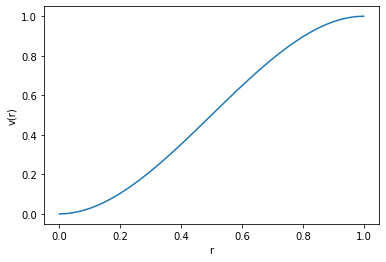

In [14]:
def plot_v():
    r_range=linspace(0,1)
    plot(r_range,lambdify(r,v,'numpy')(r_range))
    xlabel('r'); ylabel('v(r)')
plot_v()

### Mass injection rate

Constant density within wind radius implies $\dot\rho=\nabla\dot F_\rho$

In [10]:
dddt=simplify(1/r**2*diff(r**2*v))
dddt

2*r*(6 - 5*r)

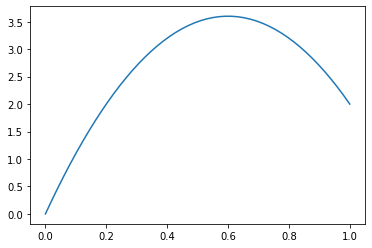

In [15]:
def plot_drho_dt():
    r_range=linspace(0,1)
    plot(r_range,lambdify(r,dddt,'numpy')(r_range))
plot_drho_dt()

### Momentum injection rate

Using the incompressible, non-viscous form of the navier stokes, neglecting gravity, we have
$\dot v+(v\cdot \nabla)v=0$ at steady state

In [29]:
dpdt = simplify(v*diff(v))
dpdt

6*r**3*(r - 1)*(2*r - 3)

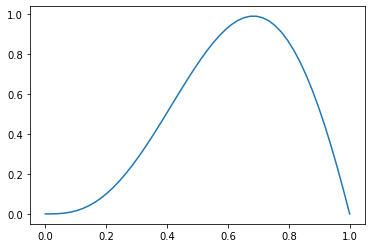

In [30]:
def plot_dp_dt():
    r_range=linspace(0,1)
    plot(r_range,lambdify(r,dpdt,'numpy')(r_range))
plot_dp_dt()

In [32]:
sympy.integrate(dpdt*r**2,(r,0,1))

3/14

## Summary of injection equations

Mass injection, with proper scaling units:
$$ \frac{\partial\rho}{\partial t} = \frac{\rho_0 v_0 }{R_0} 2r(6−5r) $$
where $v_0$ is the terminal speed, $r = R/R_0$, and
$$ \rho_0 = \frac{\dot{M}_{wind}}{4 \pi R_0^2 v_0}$$.

Momentum injection:
$$ \frac{\partial(\rho u_r)}{\partial t} = \frac{\rho_0 v_0^2 }{R_0} \, 6 r^3 (1-r) (3-2r) = v_0 \frac{\partial\rho}{\partial t} r^2(3-2r)$$

In the unpertubed case (no other external forces), the resulting wind profile is
$$ v(r) = v_0 \, r^2(3-2r)$$